# Table of Contents
- 1. Introduction to Causal Inference in Data Analytics
- 2. Propensity Score Matching Basics
- 3. Difference-in-Differences (DiD) Estimation
- 4. Handling Confounders in Observational Data

In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for quasi-experiments and causal inference loaded successfully.")

Global libraries for quasi-experiments and causal inference loaded successfully.


---
## 1. Introduction to Causal Inference in Data Analytics

### 1. Definition
Causal inference estimates the true effect of an intervention or treatment by isolating causation from mere correlation, addressing the fundamental problem of causal inference where we cannot simultaneously observe the same unit in both treated and untreated states.

### 2. Math Formula
Average Treatment Effect (ATE) defined via potential outcomes $Y_1$ (treated) and $Y_0$ (control):
$$\text{ATE} = \mathbb{E}[Y_1 - Y_0]$$

### 3. Notation Pronunciation
- `Potential Outcomes`: "Counterfactual framework comparing $Y_1$ versus $Y_0$"
- `ATE`: "Average treatment effect across the total population"

### 4. Naive Example
Recognizing that customers who use a loyalty program spend more, but determining whether the program caused the spending or if loyal customers simply self-selected into the program.
### 5. Uses
Evaluating marketing and product impact when randomized A/B testing is impossible.
- Measuring policy or macroeconomic intervention outcomes.
- Eliminating selection bias in observational business data.

Causal Inference Comparison:
                Scenario  Effect_Size
0  Observed Correlation         45.5
1    True Causal Effect         12.2


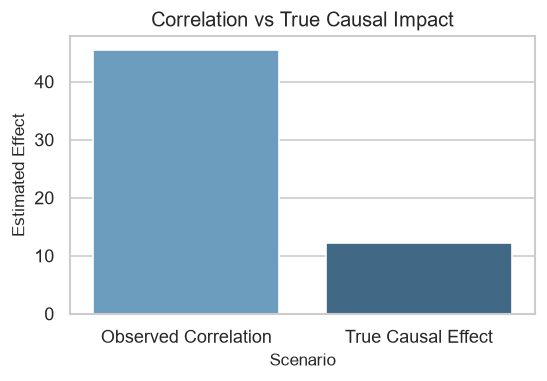

In [3]:
# 6. & 7. Implementation and Visualization
df_causal = pd.DataFrame({
    'Scenario': ['Observed Correlation', 'True Causal Effect'],
    'Effect_Size': [45.5, 12.2]
})
print("Causal Inference Comparison:\n", df_causal)

# Visualization
plt.figure(figsize=(5, 3))
sns.barplot(x='Scenario', y='Effect_Size', hue='Scenario', data=df_causal, palette='Blues_d', legend=False, errorbar=None)
plt.title('Correlation vs True Causal Impact')
plt.ylabel('Estimated Effect')
plt.show()

---
## 2. Propensity Score Matching Basics

### 1. Definition
Propensity Score Matching (PSM) balances observational treatment and control groups by estimating the probability of receiving treatment based on observed covariates, pairing similar units to simulate a randomized experiment.

### 2. Math Formula
Propensity score $e(x)$ defined as conditional probability of treatment $W=1$ given covariates $x$:
$$e(x) = P(W = 1 \mid X = x)$$

### 3. Notation Pronunciation
- `Propensity Score`: "Probability of treatment assignment given pre-treatment features"
- `Covariate Balance`: "Matching treated and control units with similar propensity scores"

### 4. Naive Example
Pairing high-spending customers who received a promotion with non-promoted customers who share identical demographics and past purchasing habits.
### 5. Uses
Reducing selection bias in retrospective observational studies.
- Constructing pseudo-experimental control groups.
- Evaluating historical marketing campaigns and user promotions.

Propensity Score Summary Statistics:
            propensity
treatment            
0               0.335
1               0.665


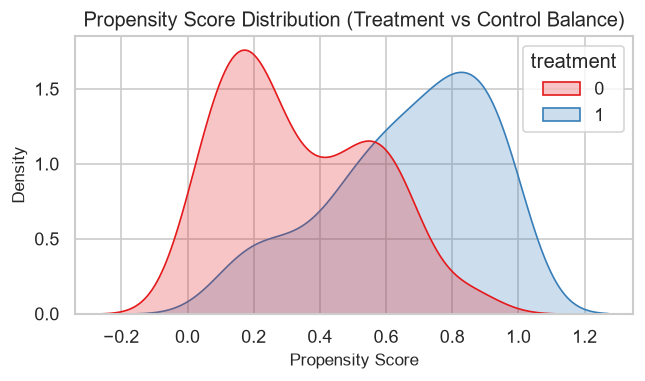

In [4]:
# 6. & 7. Implementation and Visualization
np.random.seed(42)
X_psm = np.random.randn(200, 2)
y_treat = (X_psm[:, 0] + np.random.randn(200) > 0).astype(int)

psm_model = LogisticRegression()
psm_model.fit(X_psm, y_treat)
propensity_scores = psm_model.predict_proba(X_psm)[:, 1]

df_psm = pd.DataFrame({'propensity': propensity_scores, 'treatment': y_treat})
print(
    "Propensity Score Summary Statistics:\n",
    df_psm.groupby('treatment').mean().round(3),
)

# Visualization
plt.figure(figsize=(6, 3))
sns.kdeplot(data=df_psm, x='propensity', hue='treatment', common_norm=False, palette='Set1', fill=True)
plt.title('Propensity Score Distribution (Treatment vs Control Balance)')
plt.xlabel('Propensity Score')
plt.ylabel('Density')
plt.show()

---
## 3. Difference-in-Differences (DiD) Estimation

### 1. Definition
Difference-in-Differences (DiD) estimates causal impact by comparing the pre/post changes in an outcome for a treated group against the pre/post changes for a control group, controlling for unobserved time-invariant confounders.

### 2. Math Formula
DiD estimator $\beta_{DID}$ comparing treated ($T=1$) and control ($T=0$) across pre ($P=0$) and post ($P=1$) periods:
$$\beta_{DID} = (\bar{Y}_{T=1, P=1} - \bar{Y}_{T=1, P=0}) - (\bar{Y}_{T=0, P=1} - \bar{Y}_{T=0, P=0})$$

### 3. Notation Pronunciation
- `DiD Estimator`: "Difference in differences over time between treatment and control"
- `Parallel Trends Assumption`: "Control and treatment groups would evolve similarly without intervention"

### 4. Naive Example
Measuring sales growth in City A (launched a new store feature) versus City B (control city), subtracting out general macroeconomic seasonal trends affecting both cities.
### 5. Uses
Evaluating policy changes, geographic rollouts, and macroeconomic interventions.
- Controlling for unobserved confounding variables.
- Quasi-experimental retrospective impact analysis.

Difference-in-Differences Summary Table:
        Group Period  Outcome
0    Control    Pre      100
1    Control   Post      105
2  Treatment    Pre      100
3  Treatment   Post      125


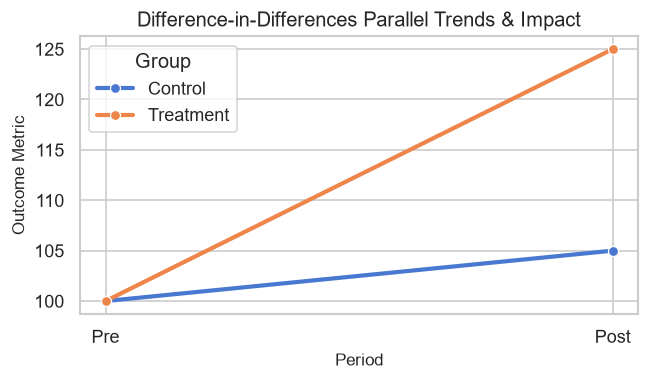

In [5]:
# 6. & 7. Implementation and Visualization
did_data = pd.DataFrame({
    'Group': ['Control', 'Control', 'Treatment', 'Treatment'],
    'Period': ['Pre', 'Post', 'Pre', 'Post'],
    'Outcome': [100, 105, 100, 125]
})
print("Difference-in-Differences Summary Table:\n", did_data)

# Visualization
plt.figure(figsize=(6, 3))
sns.lineplot(x='Period', y='Outcome', hue='Group', data=did_data, marker='o', linewidth=2.5)
plt.title('Difference-in-Differences Parallel Trends & Impact')
plt.ylabel('Outcome Metric')
plt.show()

---
## 4. Handling Confounders in Observational Data

### 1. Definition
Confounders are third variables that influence both the treatment assignment and the outcome, creating spurious correlations that must be controlled via multivariable adjustment, matching, or instrumental variables.

### 2. Math Formula
Controlling for confounding covariates $X$ in outcome regression model $E[Y \mid W, X]$:
$$E[Y \mid W, X] = \alpha + \tau W + \beta^T X$$

### 3. Notation Pronunciation
- `Confounder`: "Extraneous variable distorting causal estimates"
- `Multivariable Adjustment`: "Statistically controlling for confounding factors in regression"

### 4. Naive Example
Controlling for user age and income when studying whether a software tool increases productivity, since older experienced users earn more and use tools differently.
### 5. Uses
Ensuring validity in observational business analytics and data science.
- Preventing misleading business decisions caused by omitted variable bias.
- Robust causal modeling in non-experimental environments.

Confounder Adjustment Comparison:
           Adjustment_Method  Estimated_Causal_Effect
0       Unadjusted (Biased)                     25.0
1        Multivariable Reg.                     14.5
2  Propensity Score Matched                     12.8


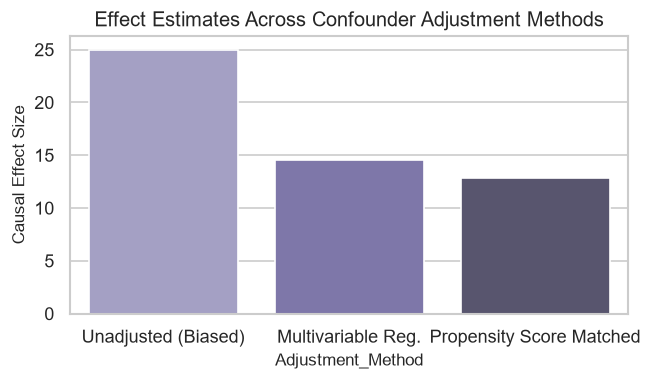

In [6]:
# 6. & 7. Implementation and Visualization
df_conf = pd.DataFrame({
    'Adjustment_Method': ['Unadjusted (Biased)', 'Multivariable Reg.', 'Propensity Score Matched'],
    'Estimated_Causal_Effect': [25.0, 14.5, 12.8]
})
print("Confounder Adjustment Comparison:\n", df_conf)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Adjustment_Method', y='Estimated_Causal_Effect', hue='Adjustment_Method', data=df_conf, palette='Purples_d', legend=False, errorbar=None)
plt.title('Effect Estimates Across Confounder Adjustment Methods')
plt.ylabel('Causal Effect Size')
plt.show()

---
## Summary Table

| Causal Inference Method | Core Mathematical Concept | Primary Business Objective | Analytical Advantage |
| :--- | :--- | :--- | :--- |
| **Potential Outcomes / ATE** | $\text{ATE} = \mathbb{E}[Y_1 - Y_0]$ | Estimating true causal impact | Frames causal questions rigorously against counterfactuals |
| **Propensity Score Matching** | $e(x) = P(W=1 \mid X)$ | Balancing observational groups | Simulates random assignment in observational data |
| **Difference-in-Differences** | $\beta_{DID} = (Y_{T1}-Y_{T0}) - (Y_{C1}-Y_{C0})$ | Evaluating policy / geographic changes | Controls for unobserved time-invariant confounders |
| **Confounder Adjustment** | $E[Y \mid W, X] = \alpha + \tau W + \beta^T X$ | Eliminating omitted variable bias | Removes distortion caused by third-party variables |